In [2]:

# Google Drive

from google.colab import drive
from pathlib import Path
import torch

drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Device:', device)

if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))


Mounted at /content/drive
Device: cuda
GPU: Tesla T4


In [3]:

# Load Landsat images and pond labels

import numpy as np

data_dir = Path('/content/drive/MyDrive/Aquaculture_GeoAI/Model_Inputs')

X = np.load(data_dir / 'landsat_1999_2014.npy')
y = np.load(data_dir / 'new_pond_labels.npy')
split = np.load(data_dir / 'spatial_split.npy')

X_single = X[:, :, 6:12]
X_temporal = X

print('Single-date:', X_single.shape)
print('Two-date:', X_temporal.shape)
print('Labels:', y.shape)
print('Split:', split.shape)

print('Training pixels:', (split == 1).sum())
print('Validation pixels:', (split == 2).sum())
print('Testing pixels:', (split == 3).sum())


Single-date: (2787, 1295, 6)
Two-date: (2787, 1295, 12)
Labels: (2787, 1295)
Split: (2787, 1295)
Training pixels: 415280
Validation pixels: 36011
Testing pixels: 44118


In [4]:

# Standardize Landsat bands using training data

train_pixels = X[split == 1]

mean = train_pixels.mean(axis=0)
std = train_pixels.std(axis=0)
std[std < 1e-6] = 1

X_scaled = (X - mean) / std

# Set non-training regions without assigned labels to zero
X_scaled[split == 0] = 0

X_single = X_scaled[:, :, 6:12]
X_temporal = X_scaled

print('Mean:', np.round(mean, 3))
print('Std:', np.round(std, 3))
print('Single-date:', X_single.shape)
print('Two-date:', X_temporal.shape)


Mean: [0.074 0.097 0.103 0.164 0.159 0.116 0.068 0.093 0.093 0.142 0.124 0.093]
Std: [0.011 0.015 0.022 0.065 0.098 0.075 0.016 0.019 0.028 0.072 0.091 0.072]
Single-date: (2787, 1295, 6)
Two-date: (2787, 1295, 12)


In [5]:

# Create 64x64 patches

patch_size = 64
stride = 32

patches = {1: [], 2: [], 3: []}
height, width = y.shape

for row in range(0, height - patch_size + 1, stride):
    for col in range(0, width - patch_size + 1, stride):

        area = split[row:row+patch_size, col:col+patch_size]

        for group in [1, 2, 3]:
            if (area == group).mean() >= 0.5:
                patches[group].append((row, col))

for group, name in [(1, 'Training'), (2, 'Validation'), (3, 'Testing')]:
    print(name, len(patches[group]))


Training 406
Validation 35
Testing 39


In [6]:

# Prepare datasets for both U-Net models

import torch
from torch.utils.data import Dataset, DataLoader

class PondDataset(Dataset):
    def __init__(self, images, labels, split, locations, group):
        self.images = images
        self.labels = labels
        self.split = split
        self.locations = locations
        self.group = group

    def __len__(self):
        return len(self.locations)

    def __getitem__(self, i):
        row, col = self.locations[i]

        img = self.images[row:row+64, col:col+64].copy()
        label = self.labels[row:row+64, col:col+64].copy()
        mask = self.split[row:row+64, col:col+64] == self.group

        img[~mask] = 0

        img = np.ascontiguousarray(img.transpose(2, 0, 1))
        label = np.ascontiguousarray(label[None])
        mask = np.ascontiguousarray(mask[None])

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(label).float(),
            torch.from_numpy(mask).float()
        )

def make_loaders(images):
    train = PondDataset(images, y, split, patches[1], 1)
    val = PondDataset(images, y, split, patches[2], 2)
    test = PondDataset(images, y, split, patches[3], 3)

    return (
        DataLoader(train, batch_size=4, shuffle=True),
        DataLoader(val, batch_size=4),
        DataLoader(test, batch_size=4)
    )

single_loaders = make_loaders(X_single)
temporal_loaders = make_loaders(X_temporal)

batch = next(iter(temporal_loaders[0]))

batch[0].shape, batch[1].shape, batch[2].shape


(torch.Size([4, 12, 64, 64]),
 torch.Size([4, 1, 64, 64]),
 torch.Size([4, 1, 64, 64]))

In [7]:

# Small U-Net for aquaculture mapping

import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self, in_ch):
        super().__init__()

        self.enc1 = DoubleConv(in_ch, 16)
        self.enc2 = DoubleConv(16, 32)
        self.pool = nn.MaxPool2d(2)

        self.middle = DoubleConv(32, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))

        m = self.middle(self.pool(e2))

        d2 = self.dec2(torch.cat([self.up2(m), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)


single_model = UNet(6).to(device)
temporal_model = UNet(12).to(device)

print('Single-date parameters:',
      sum(p.numel() for p in single_model.parameters()))

print('Two-date parameters:',
      sum(p.numel() for p in temporal_model.parameters()))


Single-date parameters: 117473
Two-date parameters: 118337


In [8]:

# Train both U-Net models

import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)

output_dir = Path('/content/drive/MyDrive/Aquaculture_GeoAI/UNet_Results')
output_dir.mkdir(parents=True, exist_ok=True)

def train_model(model, loaders, name):
    train_loader, val_loader, _ = loaders
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
    pos_weight = torch.tensor(3.0, device=device)

    best_loss = float('inf')
    wait = 0
    history = {'train': [], 'val': []}

    def loss_fn(pred, target, mask):
        loss = F.binary_cross_entropy_with_logits(
            pred, target, pos_weight=pos_weight, reduction='none'
        )
        return (loss * mask).sum() / mask.sum().clamp(min=1)

    for epoch in range(50):
        model.train()
        train_loss = 0

        for img, label, mask in train_loader:
            img, label, mask = img.to(device), label.to(device), mask.to(device)

            optimizer.zero_grad()
            loss = loss_fn(model(img), label, mask)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0

        with torch.no_grad():
            for img, label, mask in val_loader:
                img, label, mask = img.to(device), label.to(device), mask.to(device)
                val_loss += loss_fn(model(img), label, mask).item()

        train_loss /= len(train_loader)
        val_loss /= len(val_loader)

        history['train'].append(train_loss)
        history['val'].append(val_loss)

        if val_loss < best_loss - 0.0001:
            best_loss = val_loss
            wait = 0
            torch.save(model.state_dict(), output_dir / f'{name}.pth')
        else:
            wait += 1

        print(f'{name} | Epoch {epoch+1:02d} | Train {train_loss:.4f} | Val {val_loss:.4f}')

        if wait >= 8:
            break

    return history

single_history = train_model(single_model, single_loaders, 'unet_single')
temporal_history = train_model(temporal_model, temporal_loaders, 'unet_temporal')


unet_single | Epoch 01 | Train 0.8465 | Val 0.8326
unet_single | Epoch 02 | Train 0.7563 | Val 0.8200
unet_single | Epoch 03 | Train 0.7465 | Val 0.7031
unet_single | Epoch 04 | Train 0.7410 | Val 0.7197
unet_single | Epoch 05 | Train 0.7340 | Val 0.7237
unet_single | Epoch 06 | Train 0.7223 | Val 0.7316
unet_single | Epoch 07 | Train 0.7080 | Val 0.7234
unet_single | Epoch 08 | Train 0.7051 | Val 0.7460
unet_single | Epoch 09 | Train 0.6997 | Val 0.6971
unet_single | Epoch 10 | Train 0.6922 | Val 0.7533
unet_single | Epoch 11 | Train 0.6881 | Val 0.7227
unet_single | Epoch 12 | Train 0.6827 | Val 0.7409
unet_single | Epoch 13 | Train 0.6690 | Val 0.7343
unet_single | Epoch 14 | Train 0.6706 | Val 0.7916
unet_single | Epoch 15 | Train 0.6642 | Val 0.7800
unet_single | Epoch 16 | Train 0.6480 | Val 0.8960
unet_single | Epoch 17 | Train 0.6426 | Val 0.8021
unet_temporal | Epoch 01 | Train 0.6549 | Val 0.3971
unet_temporal | Epoch 02 | Train 0.4794 | Val 0.3333
unet_temporal | Epoch 03 | 

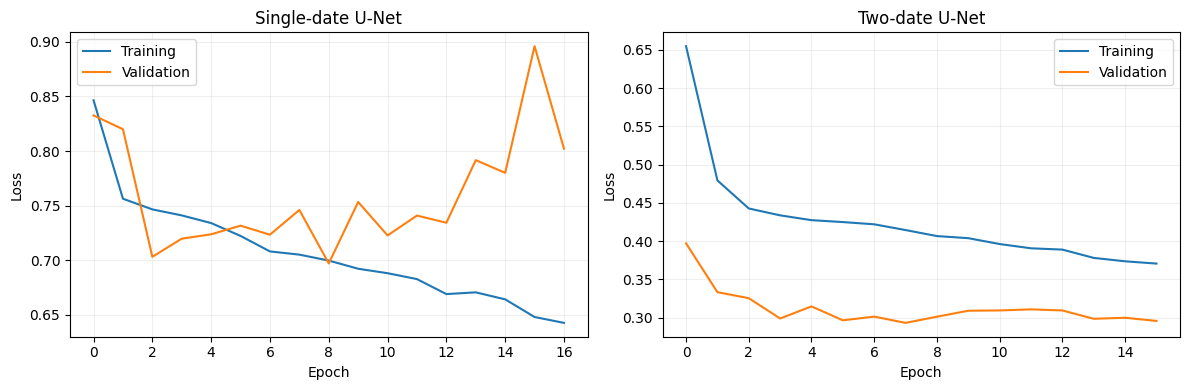

In [9]:

# Compare training and validation loss

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (name, history) in enumerate([
    ('Single-date U-Net', single_history),
    ('Two-date U-Net', temporal_history)
]):
    ax[i].plot(history['train'], label='Training')
    ax[i].plot(history['val'], label='Validation')
    ax[i].set_title(name)
    ax[i].set_xlabel('Epoch')
    ax[i].set_ylabel('Loss')
    ax[i].legend()
    ax[i].grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [10]:

# Validation predictions for both models

from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score

def predict_area(model, images, group):
    model.eval()

    prob_sum = np.zeros(y.shape, dtype=np.float32)
    prob_count = np.zeros(y.shape, dtype=np.float32)

    with torch.no_grad():
        for row, col in patches[group]:
            img = images[row:row+64, col:col+64].copy()
            mask = split[row:row+64, col:col+64] == group
            img[~mask] = 0

            tensor = torch.from_numpy(
                img.transpose(2, 0, 1).copy()
            ).float().unsqueeze(0).to(device)

            prob = torch.sigmoid(model(tensor)).squeeze().cpu().numpy()

            prob_sum[row:row+64, col:col+64] += prob * mask
            prob_count[row:row+64, col:col+64] += mask

    probabilities = np.divide(
        prob_sum, prob_count,
        out=np.zeros_like(prob_sum),
        where=prob_count > 0
    )

    return probabilities, (prob_count > 0) & (split == group)


single_model.load_state_dict(
    torch.load(output_dir / 'unet_single.pth',
               map_location=device, weights_only=True)
)

temporal_model.load_state_dict(
    torch.load(output_dir / 'unet_temporal.pth',
               map_location=device, weights_only=True)
)

single_prob, single_mask = predict_area(single_model, X_single, 2)
temporal_prob, temporal_mask = predict_area(temporal_model, X_temporal, 2)

val_mask = single_mask & temporal_mask

print('Validation pixels:', val_mask.sum())
print('New pond pixels:', int(y[val_mask].sum()))


Validation pixels: 35600
New pond pixels: 10864


In [11]:

# Compare validation F1 and IoU

import pandas as pd

true = y[val_mask].astype(np.uint8)
scores = {
    'Single-date': single_prob[val_mask],
    'Two-date': temporal_prob[val_mask]
}

results = []

for name, prob in scores.items():
    for t in np.arange(0.1, 0.91, 0.05):
        pred = (prob >= t).astype(np.uint8)

        results.append({
            'Model': name,
            'Threshold': round(float(t), 2),
            'Precision': precision_score(true, pred, zero_division=0),
            'Recall': recall_score(true, pred, zero_division=0),
            'F1': f1_score(true, pred, zero_division=0),
            'IoU': jaccard_score(true, pred, zero_division=0)
        })

val_results = pd.DataFrame(results)

best_results = val_results.loc[
    val_results.groupby('Model')['F1'].idxmax()
].reset_index(drop=True)

display(best_results.round(3))


,Model,Threshold,Precision,Recall,F1,IoU
0,Single-date,0.40,0.625,0.934,0.749,0.598
1,Two-date,0.75,0.885,0.904,0.895,0.809


In [12]:

# Test both models in Gabura

single_test, mask1 = predict_area(single_model, X_single, 3)
temporal_test, mask2 = predict_area(temporal_model, X_temporal, 3)

test_mask = mask1 & mask2
test_true = y[test_mask].astype(np.uint8)

results = []

for name, prob in [('Single-date', single_test), ('Two-date', temporal_test)]:
    threshold = float(best_results.loc[
        best_results['Model'] == name, 'Threshold'
    ].iloc[0])

    pred = (prob[test_mask] >= threshold).astype(np.uint8)

    results.append({
        'Model': name,
        'Threshold': threshold,
        'Precision': precision_score(test_true, pred, zero_division=0),
        'Recall': recall_score(test_true, pred, zero_division=0),
        'F1': f1_score(test_true, pred, zero_division=0),
        'IoU': jaccard_score(test_true, pred, zero_division=0)
    })

test_results = pd.DataFrame(results)

print('Test pixels:', test_mask.sum())
print('New pond pixels:', test_true.sum())

display(test_results.round(3))


Test pixels: 43692
New pond pixels: 11411


,Model,Threshold,Precision,Recall,F1,IoU
0,Single-date,0.40,0.388,0.942,0.550,0.379
1,Two-date,0.75,0.810,0.888,0.847,0.735


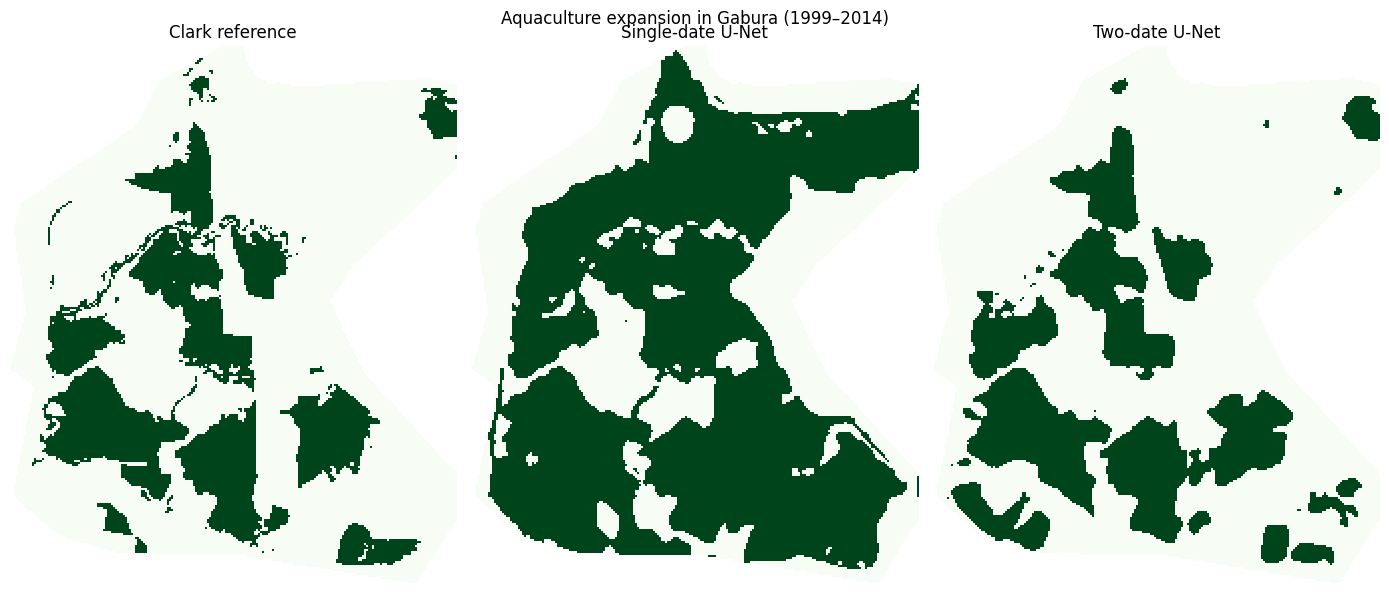

In [13]:

# Compare pond expansion predictions in Gabura

import matplotlib.pyplot as plt
import numpy as np

single_threshold = float(best_results.loc[
    best_results['Model'] == 'Single-date', 'Threshold'
].iloc[0])

temporal_threshold = float(best_results.loc[
    best_results['Model'] == 'Two-date', 'Threshold'
].iloc[0])

reference = np.ma.masked_where(~test_mask, y)
single_map = np.ma.masked_where(
    ~test_mask, (single_test >= single_threshold).astype(int)
)
temporal_map = np.ma.masked_where(
    ~test_mask, (temporal_test >= temporal_threshold).astype(int)
)

rows, cols = np.where(test_mask)
r1, r2 = rows.min(), rows.max() + 1
c1, c2 = cols.min(), cols.max() + 1

maps = [reference, single_map, temporal_map]
titles = ['Clark reference', 'Single-date U-Net', 'Two-date U-Net']

fig, ax = plt.subplots(1, 3, figsize=(14, 6))

for i in range(3):
    ax[i].imshow(
        maps[i][r1:r2, c1:c2],
        cmap='Greens',
        vmin=0,
        vmax=1,
        interpolation='nearest'
    )
    ax[i].set_title(titles[i])
    ax[i].axis('off')

plt.suptitle('Aquaculture expansion in Gabura (1999–2014)')
plt.tight_layout()
plt.show()


In [14]:

# Compare new pond area in Gabura

pixel_ha = 30 * 30 / 10000

reference_pixels = y[test_mask].sum()
single_pixels = (single_test[test_mask] >= single_threshold).sum()
temporal_pixels = (temporal_test[test_mask] >= temporal_threshold).sum()

area_results = pd.DataFrame({
    'Map': ['Clark reference', 'Single-date U-Net', 'Two-date U-Net'],
    'New pond (ha)': [
        reference_pixels * pixel_ha,
        single_pixels * pixel_ha,
        temporal_pixels * pixel_ha
    ]
})

display(area_results.round(2))


,Map,New pond (ha)
0,Clark reference,1026.99
1,Single-date U-Net,2490.66
2,Two-date U-Net,1126.62


In [15]:

# Save Gabura predictions as GeoTIF

import rasterio
import numpy as np
from pathlib import Path

gis_dir = output_dir / 'GIS_Outputs'
gis_dir.mkdir(parents=True, exist_ok=True)

with rasterio.open('/content/drive/MyDrive/Aquaculture_GeoAI/Shyamnagar_Landsat_1999_2014.tif') as src:
    profile = src.profile.copy()

def save_map(name, array, nodata, dtype):
    settings = profile.copy()
    settings.update(count=1, dtype=dtype, nodata=nodata, compress='lzw')

    with rasterio.open(gis_dir / name, 'w', **settings) as dst:
        dst.write(array.astype(dtype), 1)

reference_map = np.where(test_mask, y, 255).astype(np.uint8)

single_map = np.where(
    test_mask, (single_test >= single_threshold), 255
).astype(np.uint8)

temporal_map = np.where(
    test_mask, (temporal_test >= temporal_threshold), 255
).astype(np.uint8)

single_probability = np.where(test_mask, single_test, -9999).astype(np.float32)
temporal_probability = np.where(test_mask, temporal_test, -9999).astype(np.float32)

save_map('Gabura_Reference_1999_2014.tif', reference_map, 255, 'uint8')
save_map('Gabura_Single_UNet_1999_2014.tif', single_map, 255, 'uint8')
save_map('Gabura_Temporal_UNet_1999_2014.tif', temporal_map, 255, 'uint8')

save_map('Gabura_Single_Probability.tif', single_probability, -9999, 'float32')
save_map('Gabura_Temporal_Probability.tif', temporal_probability, -9999, 'float32')

test_results.to_csv(gis_dir / 'Gabura_Test_Results.csv', index=False)
area_results.to_csv(gis_dir / 'Gabura_Area_Comparison.csv', index=False)

print('Results saved to:', gis_dir)


Results saved to: /content/drive/MyDrive/Aquaculture_GeoAI/UNet_Results/GIS_Outputs


In [16]:

# Check GeoTIFs

import rasterio

for name in [
    'Gabura_Reference_1999_2014.tif',
    'Gabura_Single_UNet_1999_2014.tif',
    'Gabura_Temporal_UNet_1999_2014.tif',
    'Gabura_Single_Probability.tif',
    'Gabura_Temporal_Probability.tif'
]:
    with rasterio.open(gis_dir / name) as src:
        print(name, src.shape, src.crs, src.nodata)


Gabura_Reference_1999_2014.tif (2787, 1295) EPSG:32645 255.0
Gabura_Single_UNet_1999_2014.tif (2787, 1295) EPSG:32645 255.0
Gabura_Temporal_UNet_1999_2014.tif (2787, 1295) EPSG:32645 255.0
Gabura_Single_Probability.tif (2787, 1295) EPSG:32645 -9999.0
Gabura_Temporal_Probability.tif (2787, 1295) EPSG:32645 -9999.0


In [17]:

# Calculate NDVI and MNDWI changes

from sklearn.linear_model import LogisticRegression

# Original unscaled reflectance values
raw = X

def index(a, b):
    return (a - b) / (a + b + 1e-6)

ndvi99 = index(raw[:, :, 3], raw[:, :, 2])
ndvi14 = index(raw[:, :, 9], raw[:, :, 8])

mndwi99 = index(raw[:, :, 1], raw[:, :, 4])
mndwi14 = index(raw[:, :, 7], raw[:, :, 10])

features = np.stack([
    ndvi14 - ndvi99,
    mndwi14 - mndwi99
], axis=-1)

features = np.nan_to_num(features)

print('Feature shape:', features.shape)


Feature shape: (2787, 1295, 2)


In [18]:

# Train logistic regression using spectral changes

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score
import pandas as pd

train_mask = split == 1

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=500)
)

baseline.fit(features[train_mask], y[train_mask])

val_prob_baseline = baseline.predict_proba(features[val_mask])[:, 1]
val_true = y[val_mask].astype(int)

results = []

for t in np.arange(0.1, 0.91, 0.05):
    pred = (val_prob_baseline >= t).astype(int)

    results.append({
        'Threshold': round(float(t), 2),
        'Precision': precision_score(val_true, pred, zero_division=0),
        'Recall': recall_score(val_true, pred, zero_division=0),
        'F1': f1_score(val_true, pred, zero_division=0),
        'IoU': jaccard_score(val_true, pred, zero_division=0)
    })

baseline_results = pd.DataFrame(results)
baseline_best = baseline_results.loc[baseline_results['F1'].idxmax()]

display(baseline_best.to_frame().T.round(3))


,Threshold,Precision,Recall,F1,IoU
11,0.65,0.864,0.864,0.864,0.761


In [19]:

# Compare all three models in Gabura

baseline_threshold = float(baseline_best['Threshold'])

baseline_prob = baseline.predict_proba(features[test_mask])[:, 1]
baseline_pred = (baseline_prob >= baseline_threshold).astype(int)

baseline_test = {
    'Model': 'Logistic regression',
    'Threshold': baseline_threshold,
    'Precision': precision_score(test_true, baseline_pred, zero_division=0),
    'Recall': recall_score(test_true, baseline_pred, zero_division=0),
    'F1': f1_score(test_true, baseline_pred, zero_division=0),
    'IoU': jaccard_score(test_true, baseline_pred, zero_division=0)
}

final_results = pd.concat([
    test_results,
    pd.DataFrame([baseline_test])
], ignore_index=True)

display(final_results.round(3))


,Model,Threshold,Precision,Recall,F1,IoU
0,Single-date,0.40,0.388,0.942,0.550,0.379
1,Two-date,0.75,0.810,0.888,0.847,0.735
2,Logistic regression,0.65,0.730,0.764,0.746,0.595


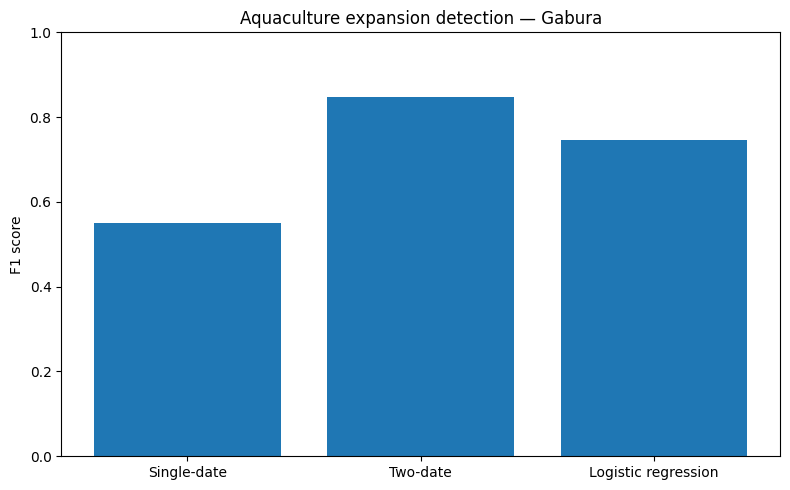

In [20]:

# Save model comparison results

final_results.to_csv(output_dir / 'Model_Comparison_1999_2014.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    final_results['Model'],
    final_results['F1']
)

ax.set_ylabel('F1 score')
ax.set_ylim(0, 1)
ax.set_title('Aquaculture expansion detection — Gabura')
plt.tight_layout()

plt.savefig(output_dir / 'Model_Comparison_1999_2014.png', dpi=200)
plt.show()


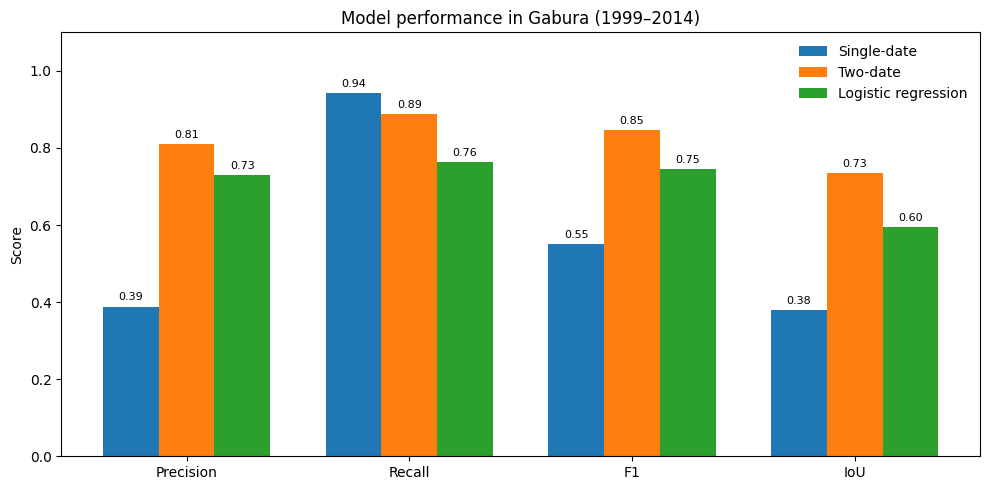

In [21]:

# Compare model accuracy

import matplotlib.pyplot as plt
import numpy as np

metrics = ['Precision', 'Recall', 'F1', 'IoU']
models = final_results['Model'].tolist()

values = final_results[metrics].to_numpy()
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

for i, model in enumerate(models):
    bars = ax.bar(x + (i - 1) * width, values[i], width, label=model)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Model performance in Gabura (1999–2014)')
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(output_dir / 'Model_Performance_Metrics.png', dpi=300)
plt.show()


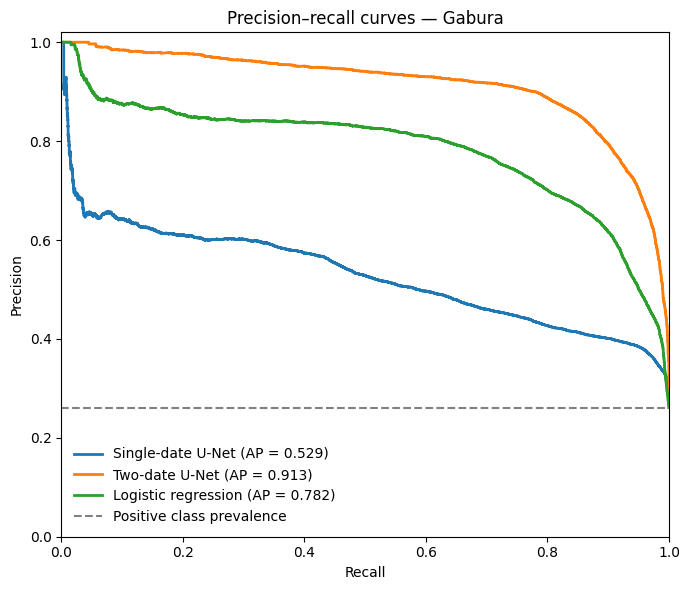

In [22]:

# Plot precision-recall curves

from sklearn.metrics import precision_recall_curve, average_precision_score

probabilities = {
    'Single-date U-Net': single_test[test_mask],
    'Two-date U-Net': temporal_test[test_mask],
    'Logistic regression': baseline_prob
}

fig, ax = plt.subplots(figsize=(7, 6))

for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(test_true, prob)
    ap = average_precision_score(test_true, prob)

    ax.plot(recall, precision, linewidth=2, label=f'{name} (AP = {ap:.3f})')

ax.axhline(test_true.mean(), color='gray', linestyle='--',
           label='Positive class prevalence')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision–recall curves — Gabura')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(output_dir / 'Precision_Recall_Curves.png', dpi=300)
plt.show()


In [23]:
# Read the saved maps

from pathlib import Path
import rasterio
import numpy as np

gis_dir = Path('/content/drive/MyDrive/Aquaculture_GeoAI/UNet_Results/GIS_Outputs')

with rasterio.open(gis_dir / 'Gabura_Reference_1999_2014.tif') as src:
    reference_map = src.read(1)
    ref_nodata = src.nodata

with rasterio.open(gis_dir / 'Gabura_Single_UNet_1999_2014.tif') as src:
    single_map = src.read(1)
    single_nodata = src.nodata

with rasterio.open(gis_dir / 'Gabura_Temporal_UNet_1999_2014.tif') as src:
    temporal_map = src.read(1)
    temporal_nodata = src.nodata

print('Reference:', reference_map.shape, 'nodata =', ref_nodata)
print('Single-date:', single_map.shape, 'nodata =', single_nodata)
print('Two-date:', temporal_map.shape, 'nodata =', temporal_nodata)

Reference: (2787, 1295) nodata = 255.0
Single-date: (2787, 1295) nodata = 255.0
Two-date: (2787, 1295) nodata = 255.0


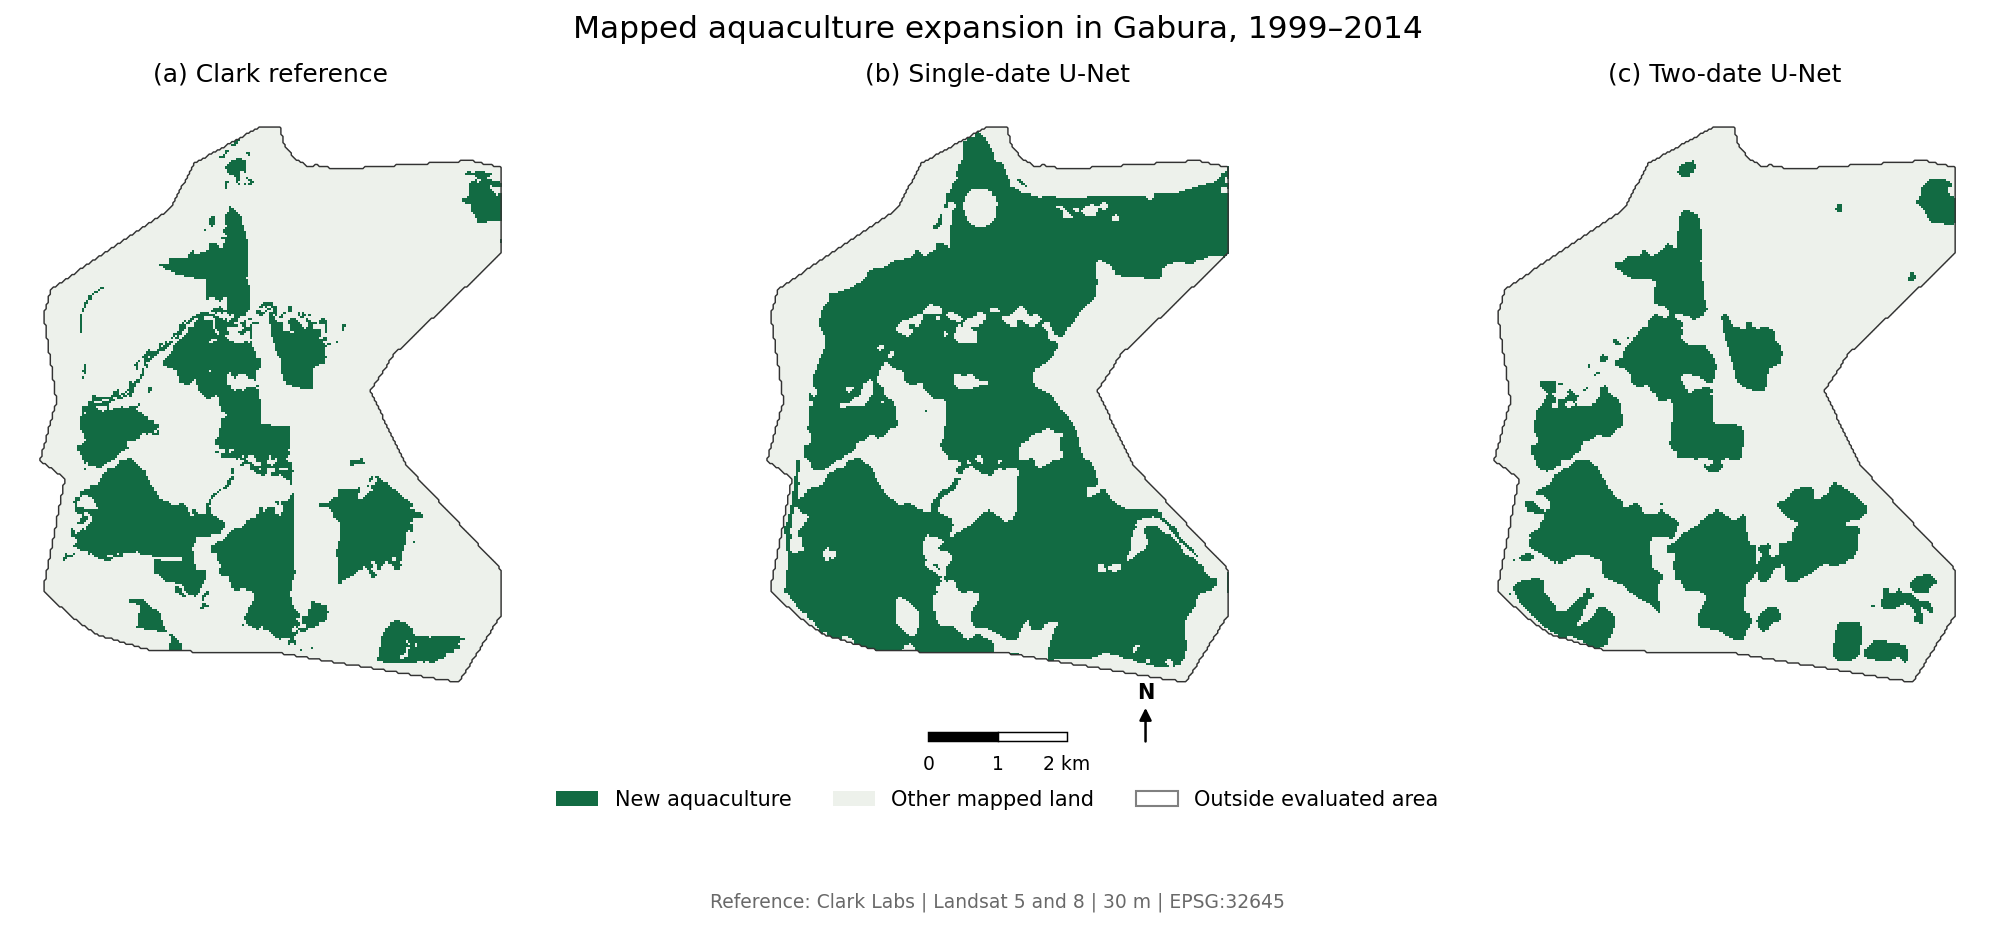

In [26]:

# Gabura aquaculture map comparison

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, FancyArrowPatch, Rectangle
from matplotlib.lines import Line2D

with rasterio.open(gis_dir / 'Gabura_Reference_1999_2014.tif') as src:
    transform = src.transform
    crs = src.crs

# Crop to the evaluated Gabura area
valid_map = ((reference_map != 255) &
             (single_map != 255) &
             (temporal_map != 255))

rows, cols = np.where(valid_map)

pad = 12
r0 = max(0, rows.min() - pad)
r1 = min(valid_map.shape[0], rows.max() + pad + 1)
c0 = max(0, cols.min() - pad)
c1 = min(valid_map.shape[1], cols.max() + pad + 1)

mask = valid_map[r0:r1, c0:c1]

maps = [
    reference_map[r0:r1, c0:c1],
    single_map[r0:r1, c0:c1],
    temporal_map[r0:r1, c0:c1]
]

maps = [np.ma.masked_where(~mask, m) for m in maps]

# Map extent in UTM coordinates
left = transform.c + c0 * transform.a
right = transform.c + c1 * transform.a
top = transform.f + r0 * transform.e
bottom = transform.f + r1 * transform.e

extent = [left, right, bottom, top]

x = left + (np.arange(c1 - c0) + 0.5) * transform.a
y_coords = top + (np.arange(r1 - r0) + 0.5) * transform.e

cmap = ListedColormap(['#edf1eb', '#126b43'])
cmap.set_bad('white')

titles = [
    '(a) Clark reference',
    '(b) Single-date U-Net',
    '(c) Two-date U-Net'
]

fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), dpi=150)

for ax, image, title in zip(axes, maps, titles):

    ax.imshow(
        image,
        cmap=cmap,
        vmin=0,
        vmax=1,
        extent=extent,
        origin='upper',
        interpolation='nearest'
    )

    ax.contour(
        x, y_coords, mask.astype(int),
        levels=[0.5],
        colors='#333333',
        linewidths=0.7
    )

    ax.set_title(title, fontsize=12, pad=10)
    ax.set_aspect('equal')
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.axis('off')

fig.suptitle(
    'Mapped aquaculture expansion in Gabura, 1999–2014',
    fontsize=15,
    y=0.97
)

# Shared legend
legend_items = [
    Patch(facecolor='#126b43', label='New aquaculture'),
    Patch(facecolor='#edf1eb', label='Other mapped land'),
    Patch(facecolor='white', edgecolor='gray',
          label='Outside evaluated area')
]

fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.135),
    ncol=3,
    frameon=False,
    fontsize=10
)

plt.subplots_adjust(
    left=0.03,
    right=0.97,
    top=0.88,
    bottom=0.26,
    wspace=0.10
)

# Scale bar centered below the maps
bar_km = 2
bar_width = axes[1].get_position().width * (bar_km * 1000 / (right - left))

x0 = 0.5 - bar_width / 2
x1 = 0.5
x2 = 0.5 + bar_width / 2
bar_y = 0.225
bar_h = 0.009

fig.add_artist(Rectangle(
    (x0, bar_y), bar_width / 2, bar_h,
    transform=fig.transFigure,
    facecolor='black',
    edgecolor='black',
    linewidth=0.7
))

fig.add_artist(Rectangle(
    (x1, bar_y), bar_width / 2, bar_h,
    transform=fig.transFigure,
    facecolor='white',
    edgecolor='black',
    linewidth=0.7
))

for xpos, label in [(x0, '0'), (x1, '1'), (x2, '2 km')]:
    fig.text(xpos, bar_y - 0.014, label,
             ha='center', va='top', fontsize=9)

# Small north arrow beside the scale bar
nx = x2 + 0.035

fig.add_artist(FancyArrowPatch(
    (nx, bar_y - 0.005),
    (nx, bar_y + 0.038),
    transform=fig.transFigure,
    arrowstyle='-|>',
    mutation_scale=12,
    linewidth=1.2,
    color='black'
))

fig.text(nx, bar_y + 0.043, 'N',
         ha='center', fontsize=10, fontweight='bold')

# Data source
fig.text(
    0.5, 0.055,
    'Reference: Clark Labs | Landsat 5 and 8 | 30 m | EPSG:32645',
    ha='center',
    fontsize=9,
    color='dimgray'
)

# Save maps
for ext in ['png', 'pdf', 'svg']:
    fig.savefig(
        output_dir / f'Gabura_Map_Comparison_Final.{ext}',
        dpi=300,
        bbox_inches='tight',
        facecolor='white'
    )

plt.show()


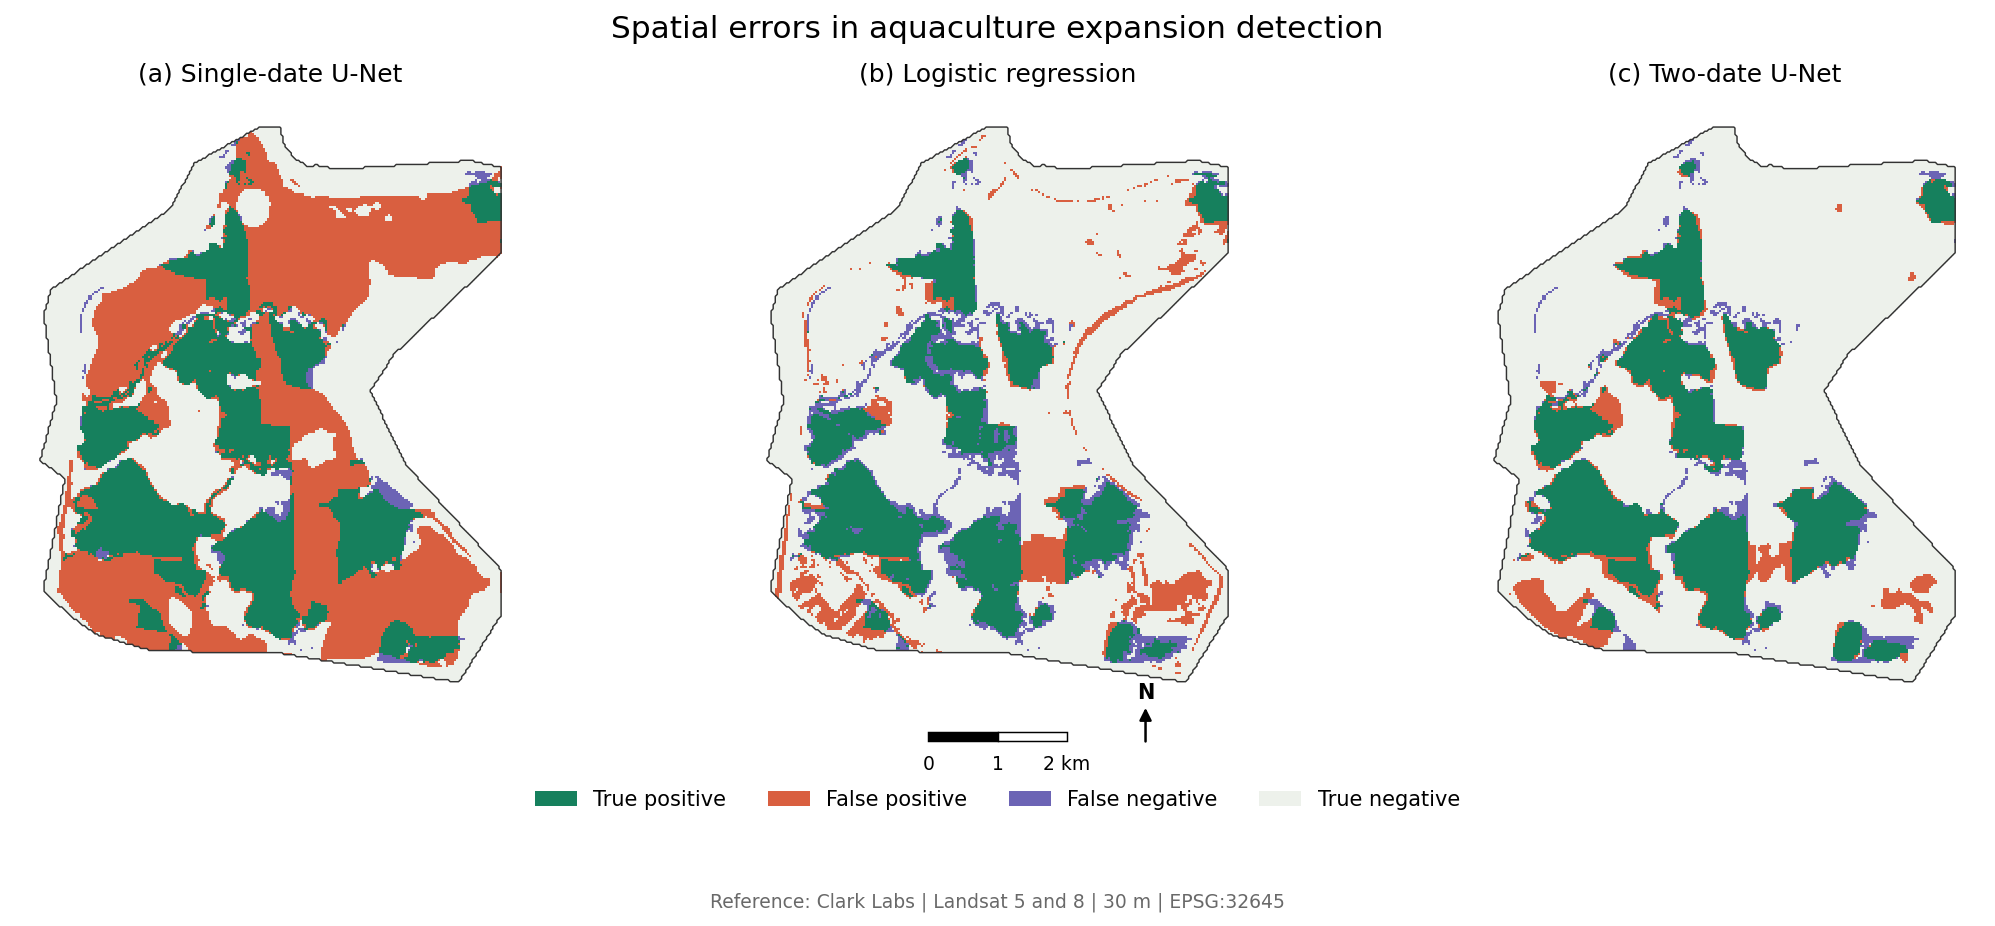

In [28]:

# Compare errors from the three models

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle, FancyArrowPatch

with rasterio.open(gis_dir / 'Gabura_Reference_1999_2014.tif') as src:
    transform = src.transform

valid_map = ((reference_map != 255) &
             (single_map != 255) &
             (temporal_map != 255))

# Logistic regression predictions on the test pixels
logistic_map = np.full(reference_map.shape, 255, dtype=np.uint8)
logistic_map[test_mask] = baseline_pred.astype(np.uint8)

valid_map &= logistic_map != 255

def get_errors(pred):
    error = np.full(reference_map.shape, 255, dtype=np.uint8)
    error[valid_map] = 0
    error[valid_map & (reference_map == 1) & (pred == 1)] = 1
    error[valid_map & (reference_map == 0) & (pred == 1)] = 2
    error[valid_map & (reference_map == 1) & (pred == 0)] = 3
    return error

single_error = get_errors(single_map)
logistic_error = get_errors(logistic_map)
temporal_error = get_errors(temporal_map)

rows, cols = np.where(valid_map)

pad = 12
r0 = max(0, rows.min() - pad)
r1 = min(valid_map.shape[0], rows.max() + pad + 1)
c0 = max(0, cols.min() - pad)
c1 = min(valid_map.shape[1], cols.max() + pad + 1)

mask = valid_map[r0:r1, c0:c1]

left = transform.c + c0 * transform.a
right = transform.c + c1 * transform.a
top = transform.f + r0 * transform.e
bottom = transform.f + r1 * transform.e
extent = [left, right, bottom, top]

x = left + (np.arange(c1-c0) + 0.5) * transform.a
y_coords = top + (np.arange(r1-r0) + 0.5) * transform.e

colors = ['#EDF1EB', '#16805D', '#D95F40', '#6C64B5']
cmap = ListedColormap(colors)
cmap.set_bad('white')

maps = [
    (single_error, '(a) Single-date U-Net'),
    (logistic_error, '(b) Logistic regression'),
    (temporal_error, '(c) Two-date U-Net')
]

fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), dpi=150)

for ax, (data, title) in zip(axes, maps):
    image = np.ma.masked_where(~mask, data[r0:r1, c0:c1])

    ax.imshow(image, cmap=cmap, vmin=-0.5, vmax=3.5,
              extent=extent, origin='upper', interpolation='nearest')

    ax.contour(x, y_coords, mask.astype(int),
               levels=[0.5], colors='#333333', linewidths=0.7)

    ax.set_title(title, fontsize=12, pad=10)
    ax.set_aspect('equal')
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.axis('off')

fig.suptitle('Spatial errors in aquaculture expansion detection',
             fontsize=15, y=0.97)

plt.subplots_adjust(left=0.03, right=0.97, top=0.88,
                    bottom=0.26, wspace=0.10)

# Scale bar
bar_width = axes[1].get_position().width * (2000 / (right - left))
x0 = 0.5 - bar_width / 2
x1 = 0.5
x2 = 0.5 + bar_width / 2
bar_y = 0.225

for start, color in [(x0, 'black'), (x1, 'white')]:
    fig.add_artist(Rectangle(
        (start, bar_y), bar_width/2, 0.009,
        transform=fig.transFigure,
        facecolor=color, edgecolor='black', linewidth=0.7
    ))

for xpos, label in [(x0, '0'), (x1, '1'), (x2, '2 km')]:
    fig.text(xpos, bar_y-0.014, label,
             ha='center', va='top', fontsize=9)

# North arrow
nx = x2 + 0.035

fig.add_artist(FancyArrowPatch(
    (nx, bar_y-0.005), (nx, bar_y+0.038),
    transform=fig.transFigure,
    arrowstyle='-|>', mutation_scale=12,
    linewidth=1.2, color='black'
))

fig.text(nx, bar_y+0.043, 'N',
         ha='center', fontsize=10, fontweight='bold')

legend = [
    Patch(facecolor=colors[1], label='True positive'),
    Patch(facecolor=colors[2], label='False positive'),
    Patch(facecolor=colors[3], label='False negative'),
    Patch(facecolor=colors[0], label='True negative')
]

fig.legend(handles=legend, loc='lower center',
           bbox_to_anchor=(0.5, 0.135),
           ncol=4, frameon=False, fontsize=10)

fig.text(0.5, 0.055,
         'Reference: Clark Labs | Landsat 5 and 8 | 30 m | EPSG:32645',
         ha='center', fontsize=9, color='dimgray')

for ext in ['png', 'pdf', 'svg']:
    fig.savefig(
        output_dir / f'Gabura_Three_Model_Error_Map.{ext}',
        dpi=300, bbox_inches='tight', facecolor='white'
    )

plt.show()


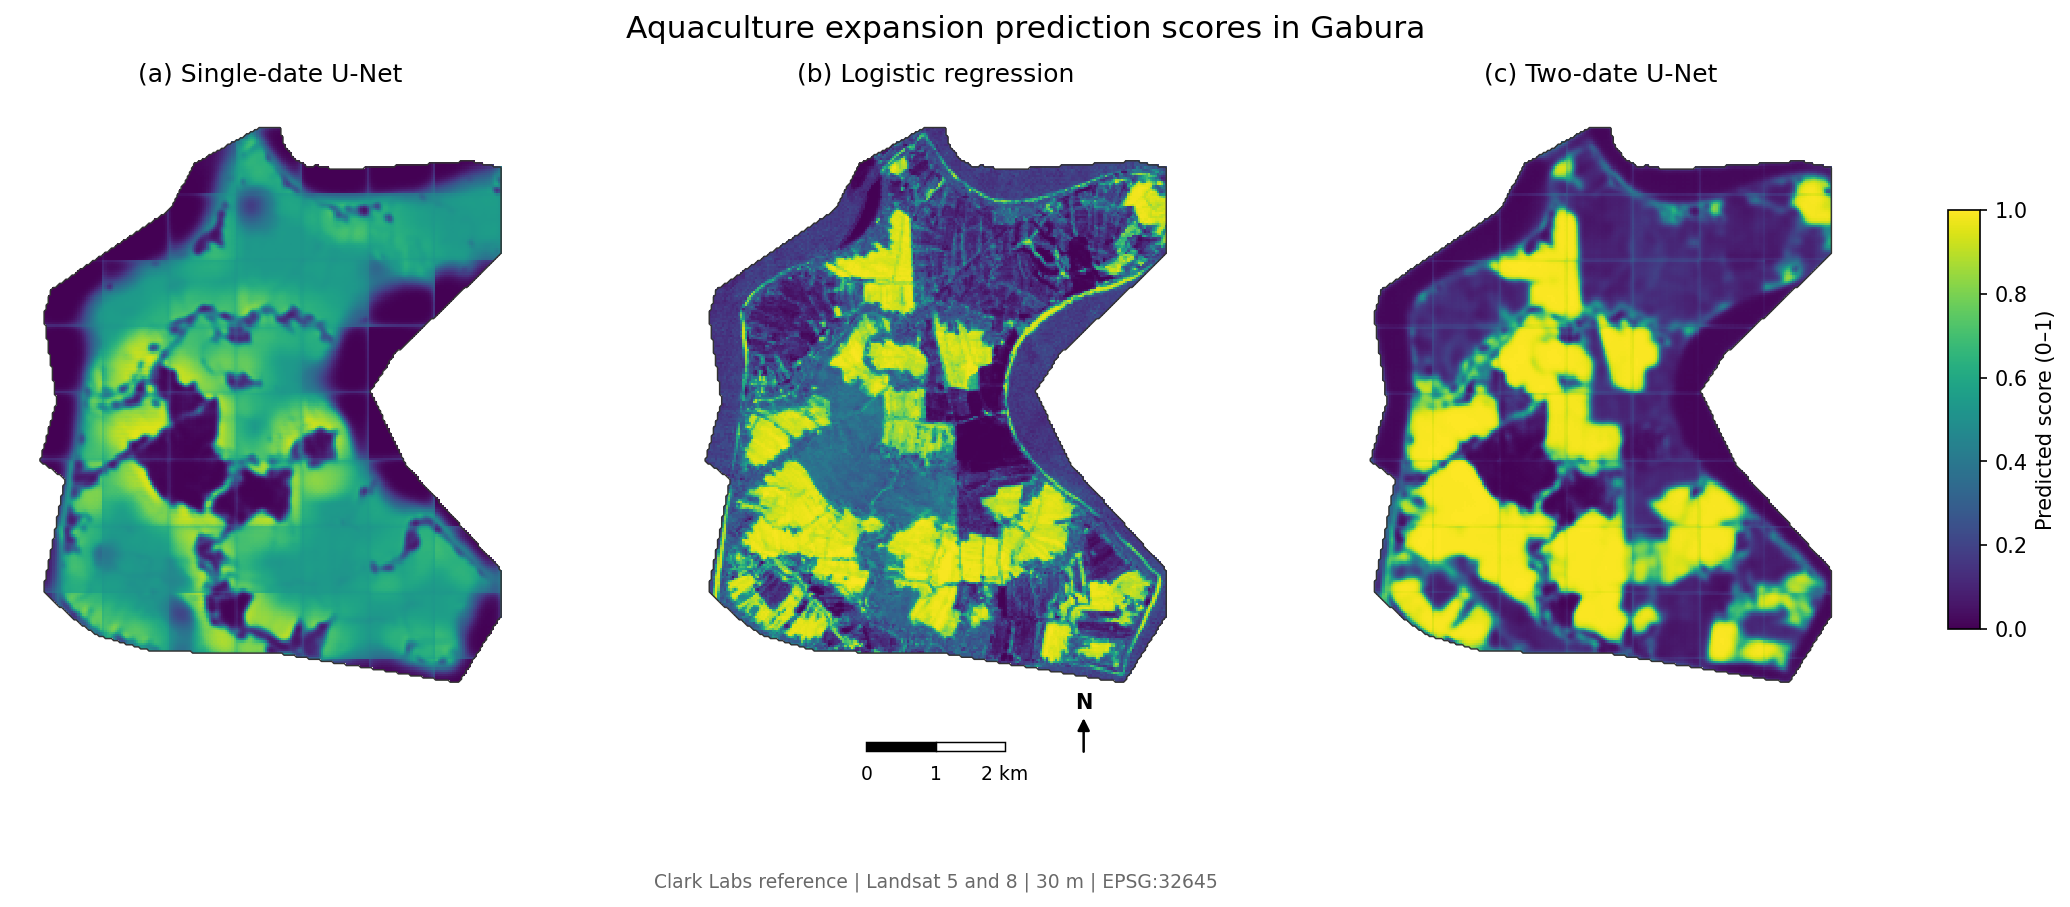

In [31]:

# Prediction score maps for Gabura

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# Logistic regression scores
logistic_prob = np.full(y.shape, np.nan, dtype=np.float32)
logistic_prob[test_mask] = baseline.predict_proba(features[test_mask])[:, 1]

with rasterio.open(gis_dir / 'Gabura_Reference_1999_2014.tif') as src:
    transform = src.transform

# Crop to Gabura test area
rows, cols = np.where(test_mask)

pad = 12
r0 = max(0, rows.min() - pad)
r1 = min(test_mask.shape[0], rows.max() + pad + 1)
c0 = max(0, cols.min() - pad)
c1 = min(test_mask.shape[1], cols.max() + pad + 1)

mask = test_mask[r0:r1, c0:c1]

left = transform.c + c0 * transform.a
right = transform.c + c1 * transform.a
top = transform.f + r0 * transform.e
bottom = transform.f + r1 * transform.e
extent = [left, right, bottom, top]

x = left + (np.arange(c1 - c0) + 0.5) * transform.a
y_coords = top + (np.arange(r1 - r0) + 0.5) * transform.e

maps = [
    (single_test, '(a) Single-date U-Net'),
    (logistic_prob, '(b) Logistic regression'),
    (temporal_test, '(c) Two-date U-Net')
]

fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), dpi=150)

for ax, (data, title) in zip(axes, maps):
    image = np.ma.masked_where(~mask, data[r0:r1, c0:c1])

    im = ax.imshow(
        image,
        cmap='viridis',
        vmin=0,
        vmax=1,
        extent=extent,
        origin='upper',
        interpolation='nearest'
    )

    ax.contour(
        x, y_coords, mask.astype(int),
        levels=[0.5],
        colors='#333333',
        linewidths=0.7
    )

    ax.set_title(title, fontsize=12, pad=10)
    ax.set_aspect('equal')
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.axis('off')

fig.suptitle(
    'Aquaculture expansion prediction scores in Gabura',
    fontsize=15,
    y=0.97
)

plt.subplots_adjust(
    left=0.03,
    right=0.89,
    top=0.88,
    bottom=0.26,
    wspace=0.10
)

# Shared color bar
cbar_ax = fig.add_axes([0.91, 0.34, 0.014, 0.43])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Predicted score (0–1)', fontsize=10)

# Centered 2 km scale bar
bar_width = axes[1].get_position().width * (2000 / (right - left))

x0 = 0.46 - bar_width / 2
x1 = 0.46
x2 = 0.46 + bar_width / 2
bar_y = 0.215
bar_h = 0.009

fig.add_artist(Rectangle(
    (x0, bar_y), bar_width / 2, bar_h,
    transform=fig.transFigure,
    facecolor='black',
    edgecolor='black',
    linewidth=0.7
))

fig.add_artist(Rectangle(
    (x1, bar_y), bar_width / 2, bar_h,
    transform=fig.transFigure,
    facecolor='white',
    edgecolor='black',
    linewidth=0.7
))

for xpos, label in [(x0, '0'), (x1, '1'), (x2, '2 km')]:
    fig.text(
        xpos, bar_y - 0.014, label,
        ha='center', va='top', fontsize=9
    )

# North arrow
nx = x2 + 0.035

fig.add_artist(FancyArrowPatch(
    (nx, bar_y - 0.005),
    (nx, bar_y + 0.038),
    transform=fig.transFigure,
    arrowstyle='-|>',
    mutation_scale=12,
    linewidth=1.2,
    color='black'
))

fig.text(
    nx, bar_y + 0.043, 'N',
    ha='center', fontsize=10, fontweight='bold'
)

fig.text(
    0.46, 0.075,
    'Clark Labs reference | Landsat 5 and 8 | 30 m | EPSG:32645',
    ha='center', fontsize=9, color='dimgray'
)

for ext in ['png', 'pdf', 'svg']:
    fig.savefig(
        output_dir / f'Gabura_Three_Model_Probability_Maps.{ext}',
        dpi=300,
        bbox_inches='tight',
        facecolor='white'
    )

plt.show()
